# How Much Is a Better Forecast Worth? Demand Forecasting and Inventory Policy on Walmart Data

A forecast only has value when it changes a decision. Accuracy tables say which model has the lowest error, but a store manager
wants to know something else: how much stock can I hold, and how many sales will I still lose?

This notebook answers that for one store's full range of 3,049 products, using the public M5 Walmart data:

1. How much more accurate is a machine learning model than the simple methods planners already use, and where?
2. Can its uncertainty estimates be trusted?
3. How much stock or lost sales does better forecasting change, once the forecasts drive a simulated replenishment process?
4. Should service targets differ by ABC class, as common practice suggests?
5. What does one more week of lead time cost?

All forecasts come from a rolling-origin backtest over the last 52 weeks of data. Every forecast uses only what was known at the
time, and all model settings were chosen on earlier weeks.

## 1. Setup

In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT / "src"))

from demand_inventory import inventory as inv
from demand_inventory import metrics as M
from demand_inventory import policies as P
from demand_inventory.data import load_panel, suspected_stockouts

STORE = "CA_1"
FIGURES, TABLES = ROOT / "reports" / "figures", ROOT / "reports" / "tables"
FIGURES.mkdir(parents=True, exist_ok=True)
TABLES.mkdir(parents=True, exist_ok=True)

# Assumptions: the data have selling prices, not costs. Sections 7 and 10 test other values.
MARGIN, COST, HOLDING = 0.30, 0.70, 0.25
REFERENCE_FILLS = (92.5, 95, 97)

INK, SOFT, GRID = "#16202E", "#51606F", "#DDE3EA"
COLOURS = {"textbook": "#eb6834", "smoothing": "#eda100", "lgbm_error": "#2a78d6", "lgbm_quantile": "#1baf7a"}
MUTED = "#A9B2BC"
SHORT = {"textbook": "Textbook", "smoothing": "Smoothing", "lgbm_error": "LightGBM + error", "lgbm_quantile": "LightGBM quantiles"}
plt.rcParams.update({"axes.titleweight": "bold", "axes.titlesize": 13, "figure.dpi": 110, "axes.edgecolor": "#C9D1D9", "font.size": 11,
                     "axes.spines.top": False, "axes.spines.right": False, "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.8,
                     "axes.axisbelow": True, "axes.titlecolor": INK, "axes.labelcolor": SOFT, "xtick.color": SOFT, "ytick.color": SOFT,
                     "legend.frameon": False, "lines.linewidth": 2})
pd.set_option("display.max_columns", 30, "display.width", 200)


def save(fig, name):
    fig.tight_layout()
    fig.savefig(FIGURES / f"{name}.png", dpi=150, bbox_inches="tight", facecolor="white")


panel = load_panel(STORE)
bt = P.load_backtest(panel)
start = bt.first_test_week
print(f"{STORE}: {panel.units.shape[0]:,} items, {panel.units.shape[1]} full weeks, {panel.weeks.week_end.iloc[0]:%d %b %Y} to {panel.weeks.week_end.iloc[-1]:%d %b %Y}")
print(f"Test weeks: {panel.weeks.week_end.iloc[start]:%d %b %Y} to {panel.weeks.week_end.iloc[-1]:%d %b %Y}")

CA_1: 3,049 items, 277 full weeks, 04 Feb 2011 to 20 May 2016
Test weeks: 29 May 2015 to 20 May 2016


## 2. The data, and what they cannot show

M5 records daily unit sales and weekly prices. Two features matter for inventory work:

- **There are no stock records.** Recorded sales are not demand, because an empty shelf also shows as zero.
- **There are no costs.** Prices are known, while margin, holding cost and lead time are assumptions stated in this notebook.

Sales are aggregated to Walmart weeks because replenishment is modelled weekly. Suspected stockouts are flagged where a week had no
sales although the previous eight weeks make that very unlikely (a Poisson probability below 0.1%). They are excluded when training
models and tested separately in section 10.

In [2]:
flags = suspected_stockouts(panel)
test_units = panel.units[:, start:]
prices = P.prices_in_test(bt)
filled_price = pd.DataFrame(prices).T.ffill().bfill().T.to_numpy()
history = np.arange(start - 52, start)
abc, xyz, cv = inv.abc_xyz(panel.units[:, history], panel.price[:, history], panel.listed[:, history])
segment = pd.Series(np.char.add(abc, xyz))

revenue = (test_units * filled_price).sum()
listed_weeks = panel.listed
quality = pd.Series({
    "Items": panel.units.shape[0],
    "Full weeks": panel.units.shape[1],
    "Units sold in test weeks": int(test_units.sum()),
    "Revenue in test weeks ($)": round(revenue),
    "Average price per unit ($)": round(revenue / test_units.sum(), 2),
    "Listed item-weeks with zero sales (%)": round((panel.units[listed_weeks] == 0).mean() * 100, 1),
    "Suspected stockout item-weeks, all (%)": round(flags[listed_weeks].mean() * 100, 2),
    "Suspected stockout item-weeks, test": int(flags[:, start:].sum()),
    "Units sold while not listed": int(panel.units[~listed_weeks].sum()),
})
quality.rename("value").to_csv(TABLES / "data_profile.csv", index_label="check")
display(quality.to_frame("value"))

by_category = pd.DataFrame({"items": panel.items.groupby("cat_id").size(),
                            "revenue": pd.Series((test_units * filled_price).sum(axis=1)).groupby(panel.items["cat_id"]).sum().round(0)})
by_category["revenue_share_pct"] = (by_category["revenue"] / by_category["revenue"].sum() * 100).round(1)
display(by_category)
segment.value_counts().sort_index().rename("items").to_frame().T

,value
Items,3049.00
Full weeks,277.00
Units sold in test weeks,1621043.00
Revenue in test weeks ($),5153939.00
Average price per unit ($),3.18
Listed item-weeks with zero sales (%),20.70
"Suspected stockout item-weeks, all (%)",1.69
"Suspected stockout item-weeks, test",2499.00
Units sold while not listed,0.00


,items,revenue,revenue_share_pct
cat_id,,,
FOODS,1437,2816245.0,54.6
HOBBIES,565,857440.0,16.6
HOUSEHOLD,1047,1480254.0,28.7


,AX,AY,AZ,BX,BY,BZ,CX,CY,CZ
items,593,561,73,145,625,155,23,353,521


**Sales are lumpy at this level.** One listed item-week in five has no sales. Segments are set from the 52 weeks *before* the test, so they
do not use later information: ABC by revenue (80% and 95% cut-offs), and XYZ by coefficient of variation (0.5 and 1.0).

## 3. How much more accurate is LightGBM?

Each method forecasts total demand over the next two weeks, because that is the period an order must cover: a one-week lead time plus a
one-week review cycle.

| Method | How it works |
|---|---|
| Moving average | Mean of the last 8 listed weeks |
| Seasonal naive | The same two weeks last year |
| Exponential smoothing | Weighted recent demand, alpha 0.2 |
| Croston (SBA) | Built for intermittent demand, alpha 0.1 |
| LightGBM | One global model on sales history, planned price, events, SNAP days, season and hierarchy, refitted every 13 weeks |

,wape_pct,bias_pct,forecasts
method,,,
LightGBM (mean),30.65,3.60,155269
Exponential smoothing,32.03,-0.43,155269
Moving average,33.69,-0.39,155269
Croston (SBA),40.11,-1.53,155269
Seasonal naive,56.41,0.44,151149


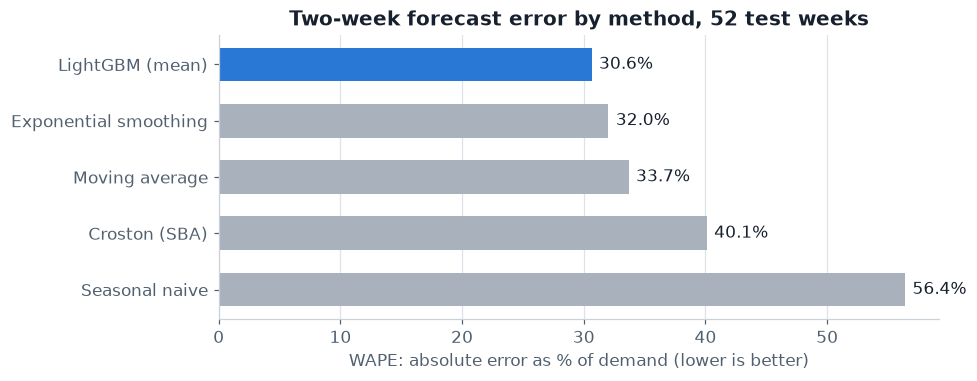

In [3]:
origins = bt.evaluated_origins()
mask = np.zeros(panel.units.shape, bool)
mask[:, origins] = True
mask &= bt.available
methods = {"Moving average": bt.baselines["moving_average"], "Seasonal naive": bt.baselines["seasonal_naive"], "Exponential smoothing": bt.baselines["smoothing"],
           "Croston (SBA)": bt.baselines["croston_sba"], "LightGBM (mean)": bt.models["mean"]}
rows = []
for name, forecast in methods.items():
    use = mask & ~np.isnan(forecast)
    rows.append({"method": name, "wape_pct": M.wape(bt.actual[use], forecast[use]), "bias_pct": M.bias(bt.actual[use], forecast[use]), "forecasts": int(use.sum())})
accuracy = pd.DataFrame(rows).sort_values("wape_pct").set_index("method")
accuracy.round(2).to_csv(TABLES / "forecast_accuracy.csv")
display(accuracy.round(2))

fig, ax = plt.subplots(figsize=(9, 3.6))
ordered = accuracy.sort_values("wape_pct", ascending=False)
ax.barh(ordered.index, ordered["wape_pct"], color=[COLOURS["lgbm_error"] if "LightGBM" in i else MUTED for i in ordered.index], height=0.6)
for y, value in enumerate(ordered["wape_pct"]):
    ax.text(value + 0.6, y, f"{value:.1f}%", va="center", color=INK)
ax.set(title="Two-week forecast error by method, 52 test weeks", xlabel="WAPE: absolute error as % of demand (lower is better)")
ax.grid(axis="y", visible=False)
save(fig, "01_forecast_accuracy")
plt.show()

In [4]:
def group_accuracy(label, group):
    use = mask & group
    y = bt.actual[use]
    return {"group": label, "forecasts": int(use.sum()), "share_of_demand_pct": y.sum() / bt.actual[mask].sum() * 100,
            "moving_average": M.wape(y, bt.baselines["moving_average"][use]), "smoothing": M.wape(y, bt.baselines["smoothing"][use]),
            "croston_sba": M.wape(y, bt.baselines["croston_sba"][use]), "lightgbm": M.wape(y, bt.models["mean"][use])}


planned = np.full(panel.units.shape, np.nan)
usual = pd.DataFrame(panel.price).T.rolling(13, min_periods=1).mean().T.to_numpy()
for origin in origins:
    known = bt.available[:, origin]
    planned[known, origin] = panel.price[known, origin + 1:origin + 3].mean(axis=1) / usual[known, origin]

rows = [group_accuracy(c, (panel.items["cat_id"].to_numpy() == c)[:, None]) for c in sorted(panel.items["cat_id"].unique())]
rows += [group_accuracy(f"Class {a}", (abc == a)[:, None]) for a in "ABC"]
rows += [group_accuracy(f"Class {x}", (xyz == x)[:, None]) for x in "XYZ"]
rows += [group_accuracy("Planned price cut of 5% or more", planned <= 0.95), group_accuracy("Planned price rise of 5% or more", planned >= 1.05),
         group_accuracy("Price within 2% of usual", np.abs(planned - 1) <= 0.02)]
by_group = pd.DataFrame(rows).set_index("group")
by_group.round(1).to_csv(TABLES / "forecast_accuracy_by_group.csv")
by_group.round(1)

,forecasts,share_of_demand_pct,moving_average,smoothing,croston_sba,lightgbm
group,,,,,,
FOODS,73080,65.2,34.6,32.6,42.5,30.8
HOBBIES,28807,12.2,34.0,32.9,36.3,32.8
HOUSEHOLD,53382,22.5,31.0,30.0,35.2,29.0
Class A,62577,71.5,30.1,28.3,36.1,27.0
Class B,47175,18.2,39.2,37.7,46.2,36.2
Class C,45517,10.3,49.1,47.7,57.5,46.4
Class X,38811,48.9,24.9,23.7,26.5,23.3
Class Y,78489,39.3,40.1,38.0,49.3,36.0
Class Z,37969,11.8,48.8,46.7,66.0,43.5


**LightGBM wins everywhere, but mostly by a few points.** Its WAPE of 30.6% compares with 32.0% for exponential smoothing and 33.7% for the moving average. Item-level
demand over two weeks is noisy, and no model removes that. Seasonal naive is by far the worst, because one past fortnight for a single item says little.

The advantage is largest when a price is about to change: 36.3% against 45.0% for smoothing after a planned cut. Those cases are only about 1.5% of demand, but they are
where a planner's simple method has no way to respond. Croston's method, designed for intermittent items, is not better here even on the erratic Z class (66.0% against 46.7%
for smoothing), partly because weekly buckets already remove much of the intermittency.

LightGBM also has a positive bias of 3.6%, probably in part because it learns from sales with suspected stockout weeks removed. The comparisons below include the effect of that bias.

## 4. Can the uncertainty estimates be trusted?

Six further LightGBM models predict quantiles directly. A 90% quantile should exceed actual demand in 90% of cases.

In [5]:
levels = [50, 70, 80, 90, 95, 98]
calibration = pd.DataFrame({"target_pct": levels, "covered_pct": [M.coverage(bt.actual[mask], bt.models[f"q{q}"][mask]) for q in levels],
                            "pinball_loss": [M.pinball(bt.actual[mask], bt.models[f"q{q}"][mask], q / 100) for q in levels]})
calibration.round(3).to_csv(TABLES / "quantile_calibration.csv", index=False)
calibration.round(2)

,target_pct,covered_pct,pinball_loss
0,50,53.26,3.07
1,70,71.13,2.80
2,80,80.58,2.34
3,90,90.01,1.57
4,95,94.94,0.99
5,98,97.95,0.52


**Yes.** Coverage is within about 3 points of the target at 50% and within 1 point elsewhere, on weeks the models never saw. Whether that translates into better stock decisions is a separate question, answered in section 6.

## 5. From forecast to replenishment

Each policy sets an order-up-to level every week. The simulation then runs week by week for each item:

1. Receive any order now due.
2. Order enough to bring stock plus orders in transit up to the target. It arrives one week later.
3. Sell what demand and stock allow. Unmet demand is lost.

| Policy | Order-up-to level |
|---|---|
| **Textbook** | Moving average × 2 + z × weekly demand deviation × √2 |
| **Smoothing** | Exponential smoothing × 2 + z × the item's recent forecast error |
| **LightGBM + error** | LightGBM mean + z × the item's recent forecast error |
| **LightGBM quantiles** | The LightGBM quantile for the target |

Forecast errors come only from forecasts already resolved at the time. All policies plan the same items in the same weeks, with the same lead time.

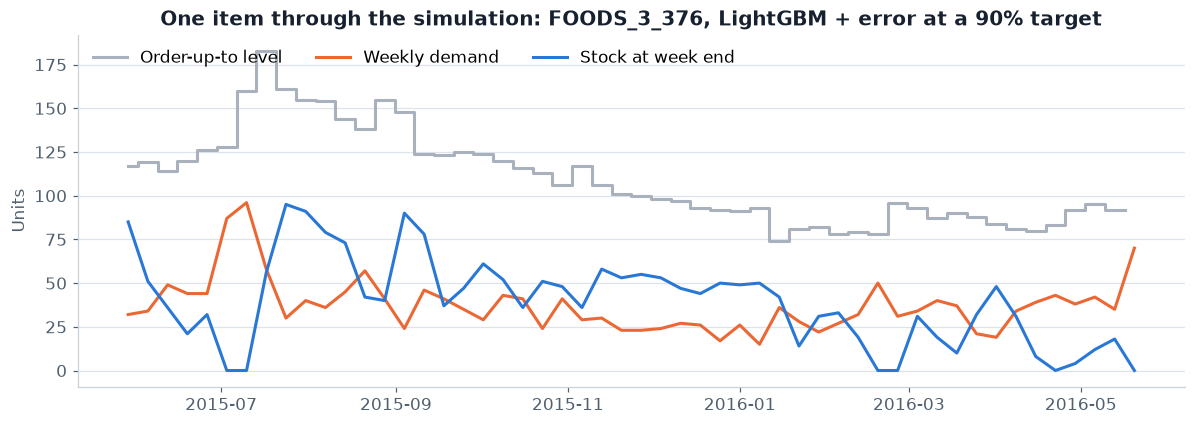

In [6]:
example_index = int(np.flatnonzero((segment == "AY").to_numpy())[np.argsort(-test_units[(segment == "AY").to_numpy()].sum(axis=1))[40]])
target = P.targets_for(bt, "lgbm_error", 0.9)
example = P.run_policy(bt, target)
week_ends = panel.weeks["week_end"].iloc[start:]

fig, ax = plt.subplots(figsize=(11, 4))
ax.step(week_ends, target[example_index], where="mid", color=MUTED, label="Order-up-to level")
ax.plot(week_ends, test_units[example_index], color="#eb6834", label="Weekly demand")
ax.plot(week_ends, example["on_hand"][example_index], color="#2a78d6", label="Stock at week end")
ax.set(title=f"One item through the simulation: {panel.items['item_id'][example_index]}, LightGBM + error at a 90% target", ylabel="Units")
ax.legend(ncol=3, loc="upper left")
ax.grid(axis="x", visible=False)
save(fig, "02_simulation_example")
plt.show()

In [7]:
frontier = P.frontier(bt, margin_ratio=MARGIN, cost_ratio=COST, holding_rate=HOLDING)
frontier["policy_name"] = frontier["policy"].map(P.POLICIES)
frontier.round(2).to_csv(TABLES / "policy_frontier.csv", index=False)
display(frontier.pivot(index="target_pct", columns="policy", values="unit_fill_pct").round(1)[list(P.POLICIES)])

policy,textbook,smoothing,lgbm_error,lgbm_quantile
target_pct,,,,
50.0,83.1,83.8,85.6,83.6
70.0,89.8,91.2,92.3,90.9
80.0,92.6,94.0,94.9,94.0
90.0,95.2,96.5,97.1,96.9
95.0,96.7,97.7,98.1,98.3
98.0,97.8,98.5,98.8,99.2


**A service target is not a fill rate.** The target is the chance of having no stockout in a cycle, while fill rate is the share of units sold. A 50% target still fills over 83% of demand, and a 90% target fills 95–97%,
so a team setting "90%" expecting 90% of units would overstock. This is the first practical point in the study: choose the target by reading the achieved fill rate, not by assuming the two match.

## 6. What does a better forecast change?

Each policy traces a curve as the target rises. Comparing curves avoids favouring a policy merely because its target happens to be more aggressive. A lower curve holds less stock for the same service.

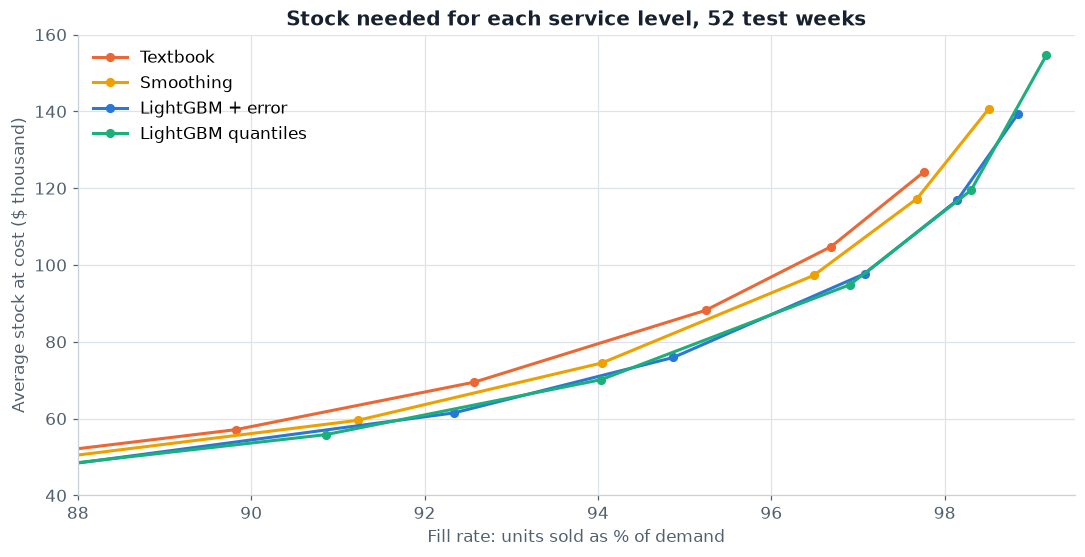

,stock_at_92.5pct_fill,stock_at_95pct_fill,stock_at_97pct_fill
Moving average + demand variability,69148.0,86488.0,110405.0
Smoothing + forecast error,66279.0,83382.0,105856.0
LightGBM + forecast error,62384.0,77193.0,96960.0
LightGBM quantiles,63201.0,78429.0,96487.0


,reference,challenger,fill_pct,saving_pct,low_pct,high_pct
0,Textbook,LightGBM + error,92.5,9.8,7.8,11.6
1,Textbook,LightGBM + error,95.0,10.7,8.8,12.3
2,Textbook,LightGBM + error,97.0,12.2,9.7,14.3
3,Smoothing,LightGBM + error,92.5,5.9,4.2,7.1
4,Smoothing,LightGBM + error,95.0,7.4,5.7,8.8
5,Smoothing,LightGBM + error,97.0,8.4,6.3,10.2
6,Textbook,Smoothing,92.5,4.1,3.4,5.3
7,Textbook,Smoothing,95.0,3.6,2.7,4.5
8,Textbook,Smoothing,97.0,4.1,3.3,4.8
9,LightGBM + error,LightGBM quantiles,92.5,-1.3,-3.1,0.2


In [8]:
fig, ax = plt.subplots(figsize=(10, 5.2))
for policy in P.POLICIES:
    line = frontier[frontier["policy"] == policy].sort_values("unit_fill_pct")
    ax.plot(line["unit_fill_pct"], line["average_stock_at_cost"] / 1000, color=COLOURS[policy], marker="o", markersize=5, label=SHORT[policy])
ax.set(title="Stock needed for each service level, 52 test weeks", xlabel="Fill rate: units sold as % of demand", ylabel="Average stock at cost ($ thousand)", xlim=(88, 99.5), ylim=(40, 160))
ax.legend(loc="upper left")
save(fig, "03_stock_service_tradeoff")
plt.show()

needed = pd.DataFrame({fill: {P.POLICIES[p]: inv.frontier_at(frontier[frontier["policy"] == p], fill) for p in P.POLICIES} for fill in REFERENCE_FILLS}).round(0)
needed.columns = [f"stock_at_{f}pct_fill" for f in REFERENCE_FILLS]
needed.to_csv(TABLES / "stock_needed_at_fill.csv", index_label="policy")
display(needed)

comparisons = [("textbook", "lgbm_error"), ("smoothing", "lgbm_error"), ("textbook", "smoothing"), ("lgbm_error", "lgbm_quantile")]
rows = []
for reference, challenger in comparisons:
    for fill in REFERENCE_FILLS:
        rows.append({"reference": SHORT[reference], "challenger": SHORT[challenger], **P.bootstrap_saving(bt, reference, challenger, fill)})
savings = pd.DataFrame(rows)
savings.round(1).to_csv(TABLES / "stock_savings.csv", index=False)
savings.round(1)

The ranges are 95% bootstrap intervals from resampling items. Three results stand out:

- **LightGBM + error needs about 11% less stock than the textbook policy at a 95% fill rate** (interval about 9–12%) and about 7% less than smoothing with the same safety stock method.
- **Part of the gain needs no machine learning.** Replacing the textbook policy's demand-variability formula with smoothing and error-based safety stock saves about 4% at a 95% fill rate.
- **Well-calibrated quantiles do not beat a simple error-based safety stock.** At a 92.5% or 97% fill rate the two cannot be separated, and at 95% quantiles need about 2% more stock. They also take six models instead of one. Calibration and decision quality are different things.

## 7. Hold less, or sell more?

Better forecasts can be spent in two ways: keep service and cut stock, or keep stock and lift service. Under this study's assumptions, the two are very different in size.

In [9]:
reference = frontier[frontier["policy"] == "textbook"].sort_values("target_pct")
base = reference[reference["target_pct"] == 90].iloc[0]
challenger = frontier[frontier["policy"] == "lgbm_error"].sort_values("average_stock_at_cost")
fill_at_same_stock = float(np.interp(base["average_stock_at_cost"], challenger["average_stock_at_cost"], challenger["unit_fill_pct"]))
stock_at_same_fill = inv.frontier_at(frontier[frontier["policy"] == "lgbm_error"], base["unit_fill_pct"])
revenue_per_year = revenue
stock_saved = base["average_stock_at_cost"] - stock_at_same_fill
points = fill_at_same_stock - base["unit_fill_pct"]
money = pd.DataFrame([
    {"route": "Keep service, hold less stock", "change": f"{stock_saved:,.0f} less stock ({stock_saved / base['average_stock_at_cost'] * 100:.1f}%)", "annual_value_usd": stock_saved * HOLDING},
    {"route": "Keep stock, lose fewer sales", "change": f"{points:.2f} points more fill", "annual_value_usd": points / 100 * revenue_per_year * MARGIN}])
money["annual_value_usd"] = money["annual_value_usd"].round(0)
money.to_csv(TABLES / "value_of_the_forecast.csv", index=False)
print(f"Base: textbook policy at a 90% target, {base['unit_fill_pct']:.2f}% fill, ${base['average_stock_at_cost']:,.0f} of stock, ${revenue_per_year:,.0f} revenue")
money

Base: textbook policy at a 90% target, 95.24% fill, $88,178 of stock, $5,153,939 revenue


,route,change,annual_value_usd
0,"Keep service, hold less stock","8,601 less stock (9.8%)",2150.0
1,"Keep stock, lose fewer sales",0.87 points more fill,13456.0


**The money is in sales, not in stock.** At this store the same forecast improvement is worth several times more as recovered margin than as lower holding cost, because holding a dollar of stock for a year costs a quarter of a dollar, while a lost sale costs its whole margin at once.

That estimate depends on assumed margin and holding rates, and uses *one store's* numbers, so it should be read as a ratio more than as a dollar figure. Section 10 varies the assumptions.

## 8. Should service targets differ by ABC class?

Many companies give A items a higher target than C items. The stock picture appears to support this at first.

,items,stock_share_pct,revenue_share_pct,fill_pct
segment,,,,
AX,593,27.7,40.6,97.8
AY,561,31.4,28.2,97.3
AZ,73,8.9,7.3,95.3
BX,145,2.3,2.6,96.3
BY,625,12.6,10.3,96.5
BZ,155,5.0,3.4,96.1
CX,23,0.3,0.3,97.3
CY,353,4.1,2.8,96.1
CZ,521,7.7,4.5,94.4


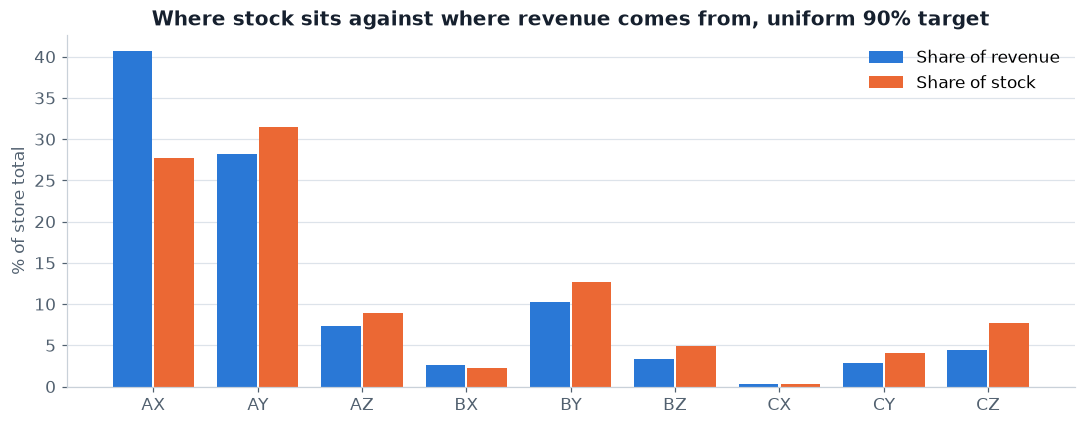

,revenue_fill_pct,stock,uniform_target_stock_at_same_fill,extra_stock_pct
plan,,,,
A 98 / B 95 / C 90,98.4,130167.1,127750.4,1.9
A 98 / B 90 / C 70,97.7,122227.5,109878.8,11.2
A 95 / B 90 / C 80,97.5,108435.2,106199.6,2.1
A 90 / B 80 / C 50,95.3,86843.7,81735.1,6.3


In [10]:
result = P.run_policy(bt, P.targets_for(bt, "lgbm_error", 0.9))
sold, lost, stock = P.item_measures(result, prices, cost_ratio=COST)
item_revenue = (result["sold"][:, 2:] * filled_price[:, 2:]).sum(axis=1)
where = pd.DataFrame({"segment": segment, "items": 1, "stock": stock, "sold": sold, "lost": lost, "revenue": item_revenue}).groupby("segment").sum()
where["stock_share_pct"] = where["stock"] / where["stock"].sum() * 100
where["revenue_share_pct"] = where["revenue"] / where["revenue"].sum() * 100
where["fill_pct"] = where["sold"] / (where["sold"] + where["lost"]) * 100
where[["items", "stock_share_pct", "revenue_share_pct", "fill_pct"]].round(1).to_csv(TABLES / "stock_by_segment.csv")
display(where[["items", "stock_share_pct", "revenue_share_pct", "fill_pct"]].round(1))

fig, ax = plt.subplots(figsize=(10, 4))
x = np.arange(len(where))
ax.bar(x - 0.2, where["revenue_share_pct"], width=0.38, color="#2a78d6", label="Share of revenue")
ax.bar(x + 0.2, where["stock_share_pct"], width=0.38, color="#eb6834", label="Share of stock")
ax.set_xticks(x, where.index)
ax.set(title="Where stock sits against where revenue comes from, uniform 90% target", ylabel="% of store total")
ax.legend()
ax.grid(axis="x", visible=False)
save(fig, "04_stock_by_segment")
plt.show()


def plan_for(a, b, c):
    return {**{f"A{x}": a for x in "XYZ"}, **{f"B{x}": b for x in "XYZ"}, **{f"C{x}": c for x in "XYZ"}}


plans = {"A 98 / B 95 / C 90": plan_for(.98, .95, .9), "A 98 / B 90 / C 70": plan_for(.98, .9, .7), "A 95 / B 90 / C 80": plan_for(.95, .9, .8), "A 90 / B 80 / C 50": plan_for(.9, .8, .5)}
uniform = frontier[frontier["policy"] == "lgbm_error"].sort_values("revenue_fill_pct")
rows = []
for name, plan in plans.items():
    tiers = inv.summarise(P.run_policy(bt, P.segment_targets(bt, "lgbm_error", segment.to_numpy(), plan)), prices, margin_ratio=MARGIN, cost_ratio=COST, holding_rate=HOLDING)
    same = float(np.interp(tiers["revenue_fill_pct"], uniform["revenue_fill_pct"], uniform["average_stock_at_cost"]))
    rows.append({"plan": name, "revenue_fill_pct": tiers["revenue_fill_pct"], "stock": tiers["average_stock_at_cost"], "uniform_target_stock_at_same_fill": same,
                 "extra_stock_pct": (tiers["average_stock_at_cost"] / same - 1) * 100})
tiers = pd.DataFrame(rows).set_index("plan")
tiers.round(1).to_csv(TABLES / "abc_service_tiers.csv")
tiers.round(1)

**In this test, ABC tiers cost more stock than one uniform target.** Every plan tried needs more stock than a uniform target that delivers the same revenue fill, from about 2% to 11% more.

Class C holds 12% of stock under a uniform target, so lowering it saves little, while pushing the A items higher is expensive. It also matches theory: the newsvendor target depends on the ratio of margin to holding cost, not on sales volume. With proportional margins assumed for all items, volume alone is not a reason to change the target.

This does not show tiers are always wrong. Real margins differ by item, and shelf space, waste and service promises can justify tiers. The point is narrower: **tiers should come from margin and constraints, not from an ABC letter**. Only four hand-set plans were tested.

## 9. What does one more week of lead time cost?

Here the backtest is repeated with a two-week lead time, so forecasts cover three weeks.

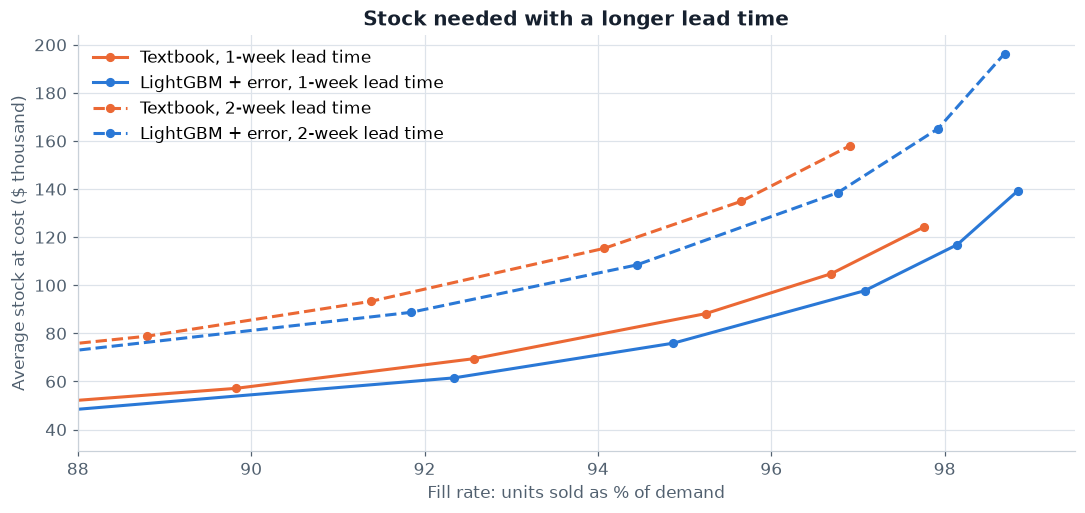

,0,1,2
fill_pct,92.5,95.0,97.0
textbook_stock_1wk,69148.1,86487.9,110405.1
textbook_stock_2wk,102464.6,126818.7,NaN
textbook_increase_pct,48.2,46.6,NaN
lgbm_error_stock_1wk,62384.1,77192.9,96960.3
lgbm_error_stock_2wk,93705.0,115605.4,143852.5
lgbm_error_increase_pct,50.2,49.8,48.4
lead_time_week_vs_forecast_ratio,4.9,4.3,NaN


In [11]:
bt_long = P.load_backtest(panel, horizon=3)
frontier_long = P.frontier(bt_long, margin_ratio=MARGIN, cost_ratio=COST, holding_rate=HOLDING)
frontier_long.round(2).to_csv(TABLES / "policy_frontier_two_week_lead_time.csv", index=False)

fig, ax = plt.subplots(figsize=(10, 4.8))
for frame, style, label in [(frontier, "-", "1-week lead time"), (frontier_long, "--", "2-week lead time")]:
    for policy in ("textbook", "lgbm_error"):
        line = frame[frame["policy"] == policy].sort_values("unit_fill_pct")
        ax.plot(line["unit_fill_pct"], line["average_stock_at_cost"] / 1000, color=COLOURS[policy], linestyle=style, marker="o", markersize=5, label=f"{SHORT[policy]}, {label}")
ax.set(title="Stock needed with a longer lead time", xlabel="Fill rate: units sold as % of demand", ylabel="Average stock at cost ($ thousand)", xlim=(88, 99.5))
ax.legend()
save(fig, "05_lead_time")
plt.show()

rows = []
for fill in REFERENCE_FILLS:
    row = {"fill_pct": fill}
    for policy in ("textbook", "lgbm_error"):
        one = inv.frontier_at(frontier[frontier["policy"] == policy], fill)
        two = inv.frontier_at(frontier_long[frontier_long["policy"] == policy], fill)
        row[f"{policy}_stock_1wk"], row[f"{policy}_stock_2wk"] = one, two
        row[f"{policy}_increase_pct"] = (two / one - 1) * 100
    row["lead_time_week_vs_forecast_ratio"] = (row["textbook_stock_2wk"] - row["textbook_stock_1wk"]) / (row["textbook_stock_1wk"] - row["lgbm_error_stock_1wk"])
    rows.append(row)
lead_time = pd.DataFrame(rows)
lead_time.round(1).to_csv(TABLES / "lead_time_cost.csv", index=False)
lead_time.round(1).T

**A week of lead time outweighs the forecast upgrade.** At a 95% fill rate, moving from one week to two raises stock by 47% with the textbook policy and 50% with LightGBM. For the textbook policy that is about $40,000 more stock, over four times the $9,300 saved by the better forecast at the same fill rate. LightGBM does not cushion the increase. Stock here is on hand only, so goods in transit would add to it.

## 10. Do the results hold elsewhere?

The analysis so far used a single store. These checks ask whether the conclusions depend on that store or on the assumptions.

store,CA_1,TX_2,WI_3
wape_moving_average,33.7,35.4,36.1
wape_smoothing,32.0,33.6,34.5
wape_lightgbm,30.6,32.7,33.0
saving_vs_textbook_pct,10.7,7.9,10.9
low_vs_textbook,8.8,5.2,9.2
high_vs_textbook,12.3,10.2,12.8
saving_vs_smoothing_pct,7.4,4.1,7.2
low_vs_smoothing,5.7,1.7,5.9
high_vs_smoothing,8.8,6.1,8.5
saving_quantile_vs_error_pct,-1.6,-1.8,-2.6


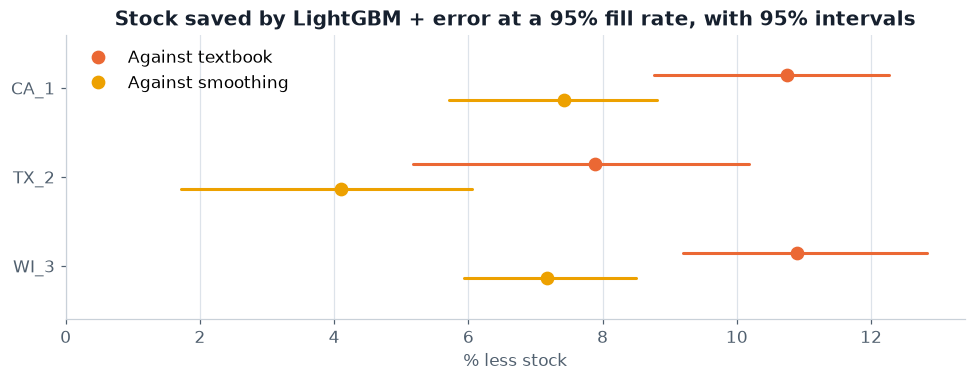

In [12]:
rows = []
for store in ["CA_1", "TX_2", "WI_3"]:
    other = P.load_backtest(load_panel(store))
    use = np.zeros(other.panel.units.shape, bool)
    use[:, other.evaluated_origins()] = True
    use &= other.available
    row = {"store": store}
    for name, matrix in {"moving_average": other.baselines["moving_average"], "smoothing": other.baselines["smoothing"], "lightgbm": other.models["mean"]}.items():
        row[f"wape_{name}"] = M.wape(other.actual[use], matrix[use])
    for reference, challenger, label in [("textbook", "lgbm_error", "vs_textbook"), ("smoothing", "lgbm_error", "vs_smoothing"), ("lgbm_error", "lgbm_quantile", "quantile_vs_error")]:
        s = P.bootstrap_saving(other, reference, challenger, 95)
        row[f"saving_{label}_pct"], row[f"low_{label}"], row[f"high_{label}"] = s["saving_pct"], s["low_pct"], s["high_pct"]
    rows.append(row)
stores = pd.DataFrame(rows).set_index("store")
stores.round(1).to_csv(TABLES / "store_robustness.csv")
display(stores.round(1).T)

fig, ax = plt.subplots(figsize=(9, 3.6))
for y, (store, row) in enumerate(stores.iloc[::-1].iterrows()):
    ax.plot([row["low_vs_textbook"], row["high_vs_textbook"]], [y + 0.14, y + 0.14], color=COLOURS["textbook"], solid_capstyle="round")
    ax.plot(row["saving_vs_textbook_pct"], y + 0.14, "o", color=COLOURS["textbook"], markersize=8, label="Against textbook" if y == 0 else None)
    ax.plot([row["low_vs_smoothing"], row["high_vs_smoothing"]], [y - 0.14, y - 0.14], color=COLOURS["smoothing"], solid_capstyle="round")
    ax.plot(row["saving_vs_smoothing_pct"], y - 0.14, "o", color=COLOURS["smoothing"], markersize=8, label="Against smoothing" if y == 0 else None)
ax.set_yticks(range(len(stores)), stores.index[::-1])
ax.set(title="Stock saved by LightGBM + error at a 95% fill rate, with 95% intervals", xlabel="% less stock", xlim=(0, None), ylim=(-0.6, len(stores) - 0.4))
ax.legend(loc="upper left")
ax.grid(axis="y", visible=False)
save(fig, "06_store_robustness")
plt.show()

In [13]:
adjusted = P.demand_with_suspected_stockouts(panel, flags)[:, start:]
added = adjusted.sum() - test_units.sum()
rows = []
for policy in P.POLICIES:
    for target_level in P.TARGETS:
        simulated = inv.simulate(P.targets_for(bt, policy, target_level), adjusted, lead_time=1)
        rows.append({"policy": policy, **inv.summarise(simulated, prices, margin_ratio=MARGIN, cost_ratio=COST, holding_rate=HOLDING)})
adjusted_frontier = pd.DataFrame(rows)
check = pd.DataFrame({
    "recorded_sales": {f"{fill}% fill": 1 - inv.frontier_at(frontier[frontier["policy"] == "lgbm_error"], fill) / inv.frontier_at(frontier[frontier["policy"] == "textbook"], fill) for fill in (92.5, 95)},
    "stockout_weeks_filled_in": {f"{fill}% fill": 1 - inv.frontier_at(adjusted_frontier[adjusted_frontier["policy"] == "lgbm_error"], fill) / inv.frontier_at(adjusted_frontier[adjusted_frontier["policy"] == "textbook"], fill) for fill in (92.5, 95)}}) * 100
check.round(1).to_csv(TABLES / "stockout_robustness.csv", index_label="comparison")
print(f"Filling in suspected stockout weeks adds {added:,.0f} units, {added / adjusted.sum() * 100:.1f}% of demand")
display(check.round(1))

rows = []
for margin in (0.2, 0.3, 0.4):
    for holding in (0.15, 0.25, 0.5):
        costed = P.frontier(bt, policies=["textbook", "lgbm_error"], margin_ratio=margin, cost_ratio=1 - margin, holding_rate=holding)
        best = costed.loc[costed.groupby("policy")["total_cost"].idxmin()].set_index("policy")
        rows.append({"margin_pct": margin * 100, "holding_rate_pct": holding * 100, "best_target_textbook": best.loc["textbook", "target_pct"], "best_target_lgbm": best.loc["lgbm_error", "target_pct"],
                     "cost_textbook": best.loc["textbook", "total_cost"], "cost_lgbm": best.loc["lgbm_error", "total_cost"],
                     "cost_reduction_pct": (1 - best.loc["lgbm_error", "total_cost"] / best.loc["textbook", "total_cost"]) * 100})
sensitivity = pd.DataFrame(rows)
sensitivity.round(1).to_csv(TABLES / "cost_sensitivity.csv", index=False)
sensitivity.round(1)

Filling in suspected stockout weeks adds 52,824 units, 3.2% of demand


,recorded_sales,stockout_weeks_filled_in
92.5% fill,9.8,10.1
95% fill,10.7,10.9


,margin_pct,holding_rate_pct,best_target_textbook,best_target_lgbm,cost_textbook,cost_lgbm,cost_reduction_pct
0,20.0,15.0,98.0,98.0,41920.3,34726.6,17.2
1,20.0,25.0,98.0,98.0,55580.3,50032.5,10.0
2,20.0,50.0,95.0,95.0,89705.5,83285.9,7.2
3,30.0,15.0,98.0,98.0,50074.3,37740.6,24.6
4,30.0,25.0,98.0,98.0,62026.8,51133.3,17.6
5,30.0,50.0,98.0,98.0,91907.9,84615.0,7.9
6,40.0,15.0,98.0,98.0,58228.3,40754.6,30.0
7,40.0,25.0,98.0,98.0,68473.2,52234.1,23.7
8,40.0,50.0,98.0,98.0,94085.7,80932.6,14.0


**The main conclusions hold.**

- **Other stores.** LightGBM is the most accurate in all three stores. At a 95% fill rate it saves 8–11% of stock against the textbook policy and 4–7% against smoothing, and every interval excludes zero. Quantile models are slightly worse than error-based safety stock in each store (2–3%).
- **Hidden stockouts.** Filling suspected stockout weeks with the item's prior rate adds 3.2% to demand and barely moves the saving (10.7% to 10.9% at a 95% fill rate). Bigger or longer stockouts would remain undetected.
- **Costs.** LightGBM has the lower simulated cost in every combination of margin and holding rate tried, by 7–30%. The cheapest target is the highest one tested (98%) in eight of nine combinations, since lost margin outweighs holding cost. This should not be read as advice to run 98% everywhere, because the cost model has no waste, shelf limit or ordering cost.

## 11. What this means for decisions

| Finding | Decision it informs |
|---|---|
| A service target is not a fill rate | Set targets by reading the achieved fill rate from a simulation, not by assuming the two are equal |
| LightGBM cuts stock by about 8–11% at the same fill rate across three stores | A global model is worth testing if a planning system can run it, and should be judged in stock and sales rather than WAPE alone |
| Most of the money is in recovered sales | Keep stock level and use the better forecast to lose fewer sales, unless space or cash is the binding constraint |
| Quantile models are calibrated but not better for stock | Start with one model and error-based safety stock, which is simpler to run and explain |
| ABC tiers needed more stock than a uniform target | Set tiers from margin and constraints, not from revenue class alone |
| One more week of lead time adds about 50% more stock, over four times the forecast saving | Before buying better forecasts, check whether a shorter or more reliable lead time is available |

## 12. Limitations

- **Sales are not demand.** There are no stock records, so hidden stockouts remain in the data. Section 10 tests a rough correction and does not remove the problem.
- **Costs are assumed.** Margin, holding rate and proportional margins across items are assumptions. Dollar values are illustrative and the comparisons are more reliable than the amounts.
- **Simplified operations.** The simulation has weekly buckets, a fixed and reliable lead time, no pack sizes or minimum orders, no shelf limits, no substitution between items and no waste, which matters for food.
- **Starting point.** Stock is measured at week end and each item starts at its target, so absolute levels are lower than a real store's total stock.
- **Replenishment affects data.** Real ordering decisions shape the sales that later train the model. The backtest cannot capture that feedback.
- **Three stores, one year.** The stores were chosen to span the three states, and the test covers one period ending in May 2016.
- **Price plans are treated as known.** A retailer knows its own planned prices, but this study uses the prices actually charged.